# TERRAIN — Fixed Fine-Tune Notebook (ISRO BAH 2026)

### Fixes applied vs original:
1. **Checkpoint path** — looks in `/kaggle/working/` (correct), not `outputs/models/`
2. **scheduler.step() order** — called AFTER `optimizer.step()`, not before
3. **Domain gap** — LISS4 included in training with 80/20 per-sensor tile split
4. **Class imbalance** — `pos_weight=8.0` added to loss; sparse-tile oversampling in DataLoader
5. **Epochs** — 30 (was 5)
6. **Grad accumulation** — 8 steps → effective batch 64 (was too small)
7. **LR** — OneCycleLR with proper warmup, encoder/decoder param groups
8. **Encoder freeze** — frozen for first 5 epochs, unfrozen with lower LR after
9. **Inference** — produces binary PNG + georeferenced GeoTIFF masks + mosaics for graph pipeline


## Cell 1 — Environment Check

In [13]:
import torch
print("torch", torch.__version__, "| cuda", torch.cuda.is_available(),
      "| devices", torch.cuda.device_count())
for i in range(torch.cuda.device_count()):
    p = torch.cuda.get_device_properties(i)
    print(i, p.name, f"{p.total_memory/1e9:.1f} GB")


torch 2.10.0+cu128 | cuda True | devices 2
0 Tesla T4 15.6 GB
1 Tesla T4 15.6 GB


## Cell 2 — Install Dependencies

In [14]:
!pip install -q --no-input timm albumentations segmentation-models-pytorch


## Cell 3 — Pull Repo Code

In [15]:
!pip install -q --no-input timm albumentations segmentation-models-pytorch scipy rasterio
import glob, os, sys, shutil, zipfile

DST = "/kaggle/working"

def _flatten(dst=DST):
    """Hoist a single wrapper dir (e.g. terrain-code/) that holds config.py."""
    entries = [e for e in sorted(os.listdir(dst)) if not e.startswith(("__MACOSX", "."))]
    if len(entries) == 1 and os.path.isdir(os.path.join(dst, entries[0])) and \
            os.path.isfile(os.path.join(dst, entries[0], "config.py")):
        wrap = os.path.join(dst, entries[0])
        for e in sorted(os.listdir(wrap)):
            s = os.path.join(wrap, e); d = os.path.join(dst, e)
            if os.path.isdir(s):
                shutil.copytree(s, d, dirs_exist_ok=True)
            else:
                shutil.copy(s, d)
        print("flattened wrapper:", entries[0])

def _merge(src_dir, dst=DST):
    for nm in sorted(os.listdir(src_dir)):
        if nm in ("dataset-metadata.json",) or nm.startswith(("__MACOSX", ".")):
            continue
        s = os.path.join(src_dir, nm); d = os.path.join(dst, nm)
        if os.path.isdir(s):
            shutil.copytree(s, d, dirs_exist_ok=True)
        elif nm.endswith(".zip"):
            with zipfile.ZipFile(s) as z:
                z.extractall(dst)
            _flatten(dst)
        else:
            shutil.copy(s, d)

PATTERNS = ("/kaggle/input/datasets/*/*", "/kaggle/input/datasets/*")

def _find_code():
    for d in [p for pat in PATTERNS for p in sorted(glob.glob(pat))]:
        if os.path.isdir(d) and os.path.basename(d).startswith("terrain-code"):
            return d
    for p in sorted(glob.glob(PATTERNS[0])) + sorted(glob.glob(PATTERNS[1])):
        if os.path.isdir(p) and os.path.isfile(os.path.join(p, "config.py")):
            return p
    return None

code_dir = _find_code()
if code_dir is None:
    raise FileNotFoundError("could not locate the code package (terrain-code*/config.py)")
_merge(code_dir)
_flatten(DST)

# safety net: if segmentation is still missing, hunt for a segmentation package
# (with __init__.py) under the code dataset and install it alongside config.py.
if not os.path.isfile(os.path.join(DST, "segmentation", "__init__.py")):
    for root in (code_dir, DST):
        for r, dirs, files in os.walk(root):
            if "segmentation" in dirs and os.path.isfile(os.path.join(r, "segmentation", "__init__.py")):
                shutil.copytree(os.path.join(r, "segmentation"),
                                os.path.join(DST, "segmentation"), dirs_exist_ok=True)
                if os.path.isfile(os.path.join(r, "config.py")) and \
                        not os.path.isfile(os.path.join(DST, "config.py")):
                    shutil.copy(os.path.join(r, "config.py"), os.path.join(DST, "config.py"))
                print("installed segmentation package from:", r)
                break

sys.path.insert(0, DST)
%cd /kaggle/working
print(sorted(os.listdir(DST))[:25])
import config, segmentation
print("import config + segmentation OK")

/kaggle/working
config.py    inference.py	       README.md
criticality  __init__.py	       requirements.txt
dashboard    kaggle_finetune.ipynb     scripts
data	     main.py		       segmentation
docs	     notebook575d9fd290.ipynb  terrain_best_best.json
experiments  notebooks		       terrain_finetuned_best.pth
finetune.py  preprocessing	       tests
graph	     __pycache__


## Cell 4 — Config + Symlink Tile Inputs

In [16]:
import os
import shutil
import glob
import zipfile
import config

SENSOR_NAMES = ["cartosat3"]
_TILE_CACHE = "/kaggle/working/_tiles"

def _has_layout(root):
    for layout in ("data/processed", "processed", ""):
        for s in SENSOR_NAMES:
            if os.path.isdir(os.path.join(root, layout, s, "image")):
                return True
    return False

def _candidates():
    found = set()
    # Kaggle mounts datasets at /kaggle/input/datasets/<owner>/<slug>/ ; try both depths.
    for pat in ("/kaggle/input/datasets/*/*", "/kaggle/input/datasets/*"):
        for p in sorted(glob.glob(pat)):
            if os.path.isdir(p):
                found.add(p)
    return sorted(found)

def _extract_if_needed(base):
    # Kaggle does NOT auto-extract .zip files inside datasets -> do it ourselves.
    zips = sorted(glob.glob(os.path.join(base, "*.zip")))
    items = [n for n in os.listdir(base) if not n.startswith(".")]
    if zips and items and all(n.endswith(".zip") for n in items):
        for zp in zips:
            tag = os.path.basename(zp)[:-4]
            out = os.path.join(_TILE_CACHE, tag)
            if not os.path.isdir(out):
                os.makedirs(out, exist_ok=True)
                with zipfile.ZipFile(zp) as z:
                    z.extractall(out)
            if _has_layout(out):
                return out
    return base

def _find_sensor(sensor):
    for base in _candidates():
        root = _extract_if_needed(base)
        for r in (f"{root}/data/processed", f"{root}/processed", root):
            cand = os.path.join(r, sensor)
            if os.path.isdir(os.path.join(cand, "image")):
                return cand
        for sub in sorted(glob.glob(os.path.join(root, "*"))):
            if not os.path.isdir(sub) or os.path.basename(sub).startswith("."):
                continue
            for r in (f"{sub}/data/processed", f"{sub}/processed", sub):
                cand = os.path.join(r, sensor)
                if os.path.isdir(os.path.join(cand, "image")):
                    return cand
    return None

def _find_norm_stats():
    for base in _candidates():
        root = _extract_if_needed(base)
        for rel in ("data/processed/_norm_stats.json",
                    "processed/_norm_stats.json",
                    "_norm_stats.json"):
            p = os.path.join(root, rel)
            if os.path.isfile(p):
                return p
        for sub in sorted(glob.glob(os.path.join(root, "*"))):
            if not os.path.isdir(sub):
                continue
            for rel in ("data/processed/_norm_stats.json",
                        "processed/_norm_stats.json",
                        "_norm_stats.json"):
                p = os.path.join(sub, rel)
                if os.path.isfile(p):
                    return p
    raise FileNotFoundError("no _norm_stats.json found in tile inputs")

config.DATA_DIR = "/kaggle/working/data/"
processed = os.path.join(config.DATA_DIR, "processed")
os.makedirs(processed, exist_ok=True)

for sensor in SENSOR_NAMES:
    while os.path.lexists(os.path.join(processed, sensor)):
        os.unlink(os.path.join(processed, sensor))
    src = _find_sensor(sensor)
    if src is None:
        raise FileNotFoundError(
            f"could not locate tiles for '{sensor}' under /kaggle/input/datasets/*/*")
    os.symlink(src, os.path.join(processed, sensor))
    print(f"linked {sensor} -> {src}")

stats_src = _find_norm_stats()
config.NORM_STATS_PATH = os.path.join(processed, "_norm_stats.json")
if not os.path.isfile(config.NORM_STATS_PATH):
    shutil.copy(stats_src, config.NORM_STATS_PATH)
print("NORM_STATS_PATH ->", config.NORM_STATS_PATH)

linked cartosat3 -> /kaggle/input/datasets/mayanktiwari18/terrain-tiles-cartosat3/data/processed/cartosat3
linked liss4 -> /kaggle/input/datasets/mayanktiwari18/terrain-tiles-liss4-s21/data/processed/liss4
linked sentinel2 -> /kaggle/input/datasets/mayanktiwari18/terrain-tiles-liss4-s21/data/processed/sentinel2
NORM_STATS_PATH -> /kaggle/working/data/processed/_norm_stats.json
EPOCHS=30 | BATCH=8 | GRAD_ACCUM=8
ENCODER_LR=3e-05 | DECODER_LR=0.0003
POS_WEIGHT=8.0 | FREEZE_EPOCHS=5
TRAIN_SENSORS=['cartosat3', 'sentinel2', 'liss4'] | VAL_SPLIT=0.2


## Cell 5 — Build Train/Val Split (All Sensors, Per-Tile Split)

In [17]:
import os
import random
import numpy as np
import rasterio
import torch
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import config

# ── Inline dataset that splits per-sensor by tile index (FIX 3) ────────────
class FixedMultiSensorDataset(Dataset):
    """
    Loads tiles from all sensors. Splits last VAL_SPLIT_FRACTION tiles
    of each sensor for validation — no sensor holdout.
    Computes per-tile road density for sparse oversampling (FIX 3).
    """
    def __init__(self, split="train", transform=None):
        self.split = split
        self.transform = transform
        self.items = []          # (sensor, img_path, mask_path)
        self.weights = []        # sampling weight per tile

        processed = os.path.join(config.DATA_DIR, "processed")
        for sensor in config.TRAIN_SENSORS:
            sensor_dir = os.path.join(processed, sensor)
            img_dir  = os.path.join(sensor_dir, "image")
            mask_dir = os.path.join(sensor_dir, "mask")
            if not os.path.isdir(img_dir):
                print(f"WARNING: {img_dir} not found, skipping {sensor}")
                continue
            fnames = sorted(os.listdir(img_dir))
            n = len(fnames)
            cut = int(n * (1 - config.VAL_SPLIT_FRACTION))
            idxs = range(0, cut) if split == "train" else range(cut, n)
            for i in idxs:
                img_path  = os.path.join(img_dir,  fnames[i])
                mask_name = fnames[i].replace("_sat", "_mask").replace(".jpg", ".png")
                mask_path = os.path.join(mask_dir, mask_name)
                if not os.path.isfile(mask_path):
                    # try same name as image
                    mask_path = os.path.join(mask_dir, fnames[i])
                if not os.path.isfile(mask_path):
                    continue
                self.items.append((sensor, img_path, mask_path))

        if split == "train":
            self._compute_weights()
        print(f"[FixedMultiSensorDataset] {split}: {len(self.items)} tiles "
              f"from sensors {config.TRAIN_SENSORS}")

    def _compute_weights(self):
        """Sparse-tile oversampling: tiles with <5% road get 3x weight."""
        self.weights = []
        for sensor, img_path, mask_path in self.items:
            try:
                with rasterio.open(mask_path) as ds:
                    m = ds.read(1).astype(np.float32)
                road_pct = m.mean() / 255.0 if m.max() > 1 else m.mean()
            except Exception:
                road_pct = 0.1
            w = 3.0 if road_pct < 0.05 else 1.0
            self.weights.append(w)

    def __len__(self):
        return len(self.items)

    def __getitem__(self, idx):
        from segmentation.dataset import _normalize, _load_norm_stats
        sensor, img_path, mask_path = self.items[idx]
        stats = _load_norm_stats()

        with rasterio.open(img_path) as ds:
            arr = ds.read().astype(np.float32)
        with rasterio.open(mask_path) as ds:
            mask = ds.read(1).astype(np.float32)

        img = _normalize(arr, sensor, stats, config.IN_CHANNELS)
        img = torch.from_numpy(img).float()

        if mask.max() > 1:
            mask = mask / 255.0
        mask = torch.from_numpy(mask).unsqueeze(0).float()

        if self.transform and self.split == "train":
            # basic augmentation
            if random.random() > 0.5:
                img  = torch.flip(img,  dims=[2])
                mask = torch.flip(mask, dims=[2])
            if random.random() > 0.5:
                img  = torch.flip(img,  dims=[1])
                mask = torch.flip(mask, dims=[1])

        return img, mask, (sensor, 0)

tr = FixedMultiSensorDataset(split="train", transform=True)
va = FixedMultiSensorDataset(split="val")

# WeightedRandomSampler for sparse-tile oversampling
sampler = WeightedRandomSampler(
    weights=torch.tensor(tr.weights, dtype=torch.float),
    num_samples=len(tr),
    replacement=True
)

train_loader = DataLoader(tr, batch_size=config.BATCH_SIZE,
                          sampler=sampler, num_workers=4, pin_memory=True)
val_loader   = DataLoader(va, batch_size=config.BATCH_SIZE,
                          shuffle=False, num_workers=4, pin_memory=True)

print(f"train batches: {len(train_loader)} | val batches: {len(val_loader)}")


[FixedMultiSensorDataset] train: 7358 tiles from sensors ['cartosat3', 'sentinel2', 'liss4']
[FixedMultiSensorDataset] val: 1840 tiles from sensors ['cartosat3', 'sentinel2', 'liss4']
train batches: 920 | val batches: 230


## Cell 6 — Load Model + Checkpoint (FIX 1: Correct Path)

In [18]:
import torch
import timm
from segmentation.model import SwinUNet
import config

device = torch.device("cuda")
model = SwinUNet(condition_on_gsd=False)

# FIX 1: correct checkpoint paths in priority order
CKPT_PATHS = [
    "/kaggle/working/terrain_best.pth",
    "/kaggle/working/terrain_best_gpu0.pth",
    "/kaggle/working/terrain_finetuned_best.pth",
]

ckpt_loaded = False
for ckpt_path in CKPT_PATHS:
    if os.path.isfile(ckpt_path):
        sd = torch.load(ckpt_path, map_location="cpu")
        sd = {k.replace("module.", ""): v for k, v in sd.items()}
        missing, unexpected = model.load_state_dict(sd, strict=False)
        print(f"[ckpt] loaded {ckpt_path}")
        print(f"  missing={len(missing)} unexpected={len(unexpected)}")
        ckpt_loaded = True
        break

if not ckpt_loaded:
    print("[ckpt] NO checkpoint found — starting from timm pretrained only")

# Reload Swin encoder from timm ImageNet weights (resets backbone to strong init)
try:
    swin = timm.create_model("swin_tiny_patch4_window7_224", pretrained=True)
    enc_sd  = swin.state_dict()
    model_sd = model.state_dict()
    copied = 0
    for k, v in enc_sd.items():
        # map timm keys to model encoder keys
        for prefix in ("encoder.", "backbone.", "swin."):
            mk = prefix + k
            if mk in model_sd and model_sd[mk].shape == v.shape:
                model_sd[mk] = v
                copied += 1
                break
    model.load_state_dict(model_sd, strict=False)
    print(f"[timm] reloaded {copied} encoder layers from swin_tiny pretrained")
except Exception as e:
    print(f"[timm] encoder reload skipped: {e}")

n = sum(p.numel() for p in model.parameters())
print(f"params: {n/1e6:.2f}M")
model = model.to(device)


[ckpt] loaded /kaggle/working/terrain_finetuned_best.pth
  missing=0 unexpected=0
[timm] reloaded 172 encoder layers from swin_tiny pretrained
params: 35.32M


## Cell 7 — Fine-Tune Loop (All Fixes Applied)

In [20]:
import torch
import torch.nn as nn
from torch.optim import AdamW
from torch.optim.lr_scheduler import OneCycleLR
from torch.cuda.amp import GradScaler, autocast
import json, os, time
import config
# ── Helper: freeze / unfreeze encoder ──────────────────────────────────────
def set_encoder_grad(model, requires_grad):
    for name, param in model.named_parameters():
        if any(k in name for k in ("encoder", "backbone", "swin", "patch_embed", "layers")):
            param.requires_grad = requires_grad
# FIX: freeze encoder for first FREEZE_ENCODER_EPOCHS
set_encoder_grad(model, requires_grad=False)
print(f"[freeze] encoder frozen for first {config.FREEZE_ENCODER_EPOCHS} epochs")
# ── Two param groups: encoder (low LR) + decoder (high LR) ────────────────
encoder_params = [p for n, p in model.named_parameters()
                  if any(k in n for k in ("encoder","backbone","swin","patch_embed","layers"))]
decoder_params = [p for n, p in model.named_parameters()
                  if not any(k in n for k in ("encoder","backbone","swin","patch_embed","layers"))]
optimizer = AdamW([
    {"params": encoder_params, "lr": config.ENCODER_LR},
    {"params": decoder_params, "lr": config.DECODER_LR},
], weight_decay=1e-4)
# FIX 2 & 4: OneCycleLR — step AFTER optimizer.step()
scheduler = OneCycleLR(
    optimizer,
    max_lr=[config.ENCODER_LR, config.DECODER_LR],
    epochs=config.EPOCHS,
    steps_per_epoch=max(1, len(train_loader) // config.GRAD_ACCUM),
    pct_start=config.WARMUP_FRACTION,
    anneal_strategy="cos",
    div_factor=10,
    final_div_factor=100,
)
# FIX 3: class imbalance — low POS_WEIGHT (3.0) avoids flooding roads
from segmentation.loss import TERRAIN_Loss
criterion = TERRAIN_Loss().to(device)
scaler = GradScaler()
# ── Training loop ───────────────────────────────────────────────────────────
history    = []
best_iou   = 0.0
best_epoch = 0
bad        = 0
SAVE_PATH  = "/kaggle/working/terrain_finetuned_best.pth"
for epoch in range(1, config.EPOCHS + 1):
    # ── Unfreeze encoder after FREEZE_ENCODER_EPOCHS ──────────────────────
    if epoch == config.FREEZE_ENCODER_EPOCHS + 1:
        set_encoder_grad(model, requires_grad=True)
        print(f"[freeze] encoder UNFROZEN at epoch {epoch}")
    # ── Train ──────────────────────────────────────────────────────────────
    model.train()
    running_loss = 0.0
    optimizer.zero_grad()
    for step, (imgs, masks, _) in enumerate(train_loader):
        imgs  = imgs.to(device,  non_blocking=True)
        masks = masks.to(device, non_blocking=True)
        with autocast():
            preds = model(imgs)
            loss  = criterion(preds, masks) / config.GRAD_ACCUM
        scaler.scale(loss).backward()
        running_loss += loss.item() * config.GRAD_ACCUM
        if (step + 1) % config.GRAD_ACCUM == 0:
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(optimizer)   # FIX 2: optimizer FIRST
            scaler.update()
            scheduler.step()         # FIX 2: scheduler AFTER optimizer
            optimizer.zero_grad()
    train_loss = running_loss / len(train_loader)
    # ── Validate ───────────────────────────────────────────────────────────
    model.eval()
    ious, dices, precs, recs = [], [], [], []
    with torch.no_grad():
        for imgs, masks, _ in val_loader:
            imgs  = imgs.to(device, non_blocking=True)
            masks = masks.to(device, non_blocking=True)
            with autocast():
                preds = torch.sigmoid(model(imgs))
            preds_bin = (preds > config.BEST_THRESHOLD).float()
            tp = (preds_bin * masks).sum(dim=(1,2,3))
            fp = (preds_bin * (1-masks)).sum(dim=(1,2,3))
            fn = ((1-preds_bin) * masks).sum(dim=(1,2,3))
            eps = 1e-6
            ious.append(  (tp / (tp+fp+fn+eps)).mean().item())
            dices.append(((2*tp) / (2*tp+fp+fn+eps)).mean().item())
            precs.append( (tp / (tp+fp+eps)).mean().item())
            recs.append(  (tp / (tp+fn+eps)).mean().item())
    iou   = float(np.mean(ious))
    dice  = float(np.mean(dices))
    prec  = float(np.mean(precs))
    rec   = float(np.mean(recs))
    lr_now = scheduler.get_last_lr()[-1]
    print(f"[E{epoch:02d}] loss={train_loss:.4f} | "
          f"val IoU={iou:.4f} Dice={dice:.4f} P={prec:.4f} R={rec:.4f} | lr={lr_now:.2e}")
    history.append({"epoch":epoch,"train_loss":train_loss,
                    "val_iou":iou,"val_dice":dice,
                    "val_precision":prec,"val_recall":rec,"lr":lr_now})
    if iou > best_iou:
        best_iou, best_epoch, bad = iou, epoch, 0
        torch.save(model.state_dict(), SAVE_PATH)
        print(f"  saved best -> {SAVE_PATH} (IoU={best_iou:.4f})")
    else:
        bad += 1
        if bad >= config.FINETUNE_PATIENCE:
            print(f"early stop @ E{epoch}; best IoU {best_iou:.4f} @ E{best_epoch}")
            break
print(f"\nDONE. best val IoU: {best_iou:.4f} @ epoch {best_epoch}") 
t


[freeze] encoder frozen for first 5 epochs


/tmp/ipykernel_58/3450013038.py:68: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()
/tmp/ipykernel_58/3450013038.py:93: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
/tmp/ipykernel_58/3450013038.py:117: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


[E01] loss=0.9127 | val IoU=0.2074 Dice=0.3278 P=0.2166 R=0.8380 | lr=9.79e-05
  saved best -> /kaggle/working/terrain_finetuned_best.pth (IoU=0.2074)
[E02] loss=0.8627 | val IoU=0.2145 Dice=0.3383 P=0.2231 R=0.8272 | lr=2.33e-04
  saved best -> /kaggle/working/terrain_finetuned_best.pth (IoU=0.2145)
[E03] loss=0.8433 | val IoU=0.2289 Dice=0.3567 P=0.2384 R=0.8414 | lr=3.00e-04
  saved best -> /kaggle/working/terrain_finetuned_best.pth (IoU=0.2289)
[E04] loss=0.8340 | val IoU=0.2402 Dice=0.3714 P=0.2503 R=0.8272 | lr=2.99e-04
  saved best -> /kaggle/working/terrain_finetuned_best.pth (IoU=0.2402)
[E05] loss=0.8218 | val IoU=0.2585 Dice=0.3934 P=0.2821 R=0.7626 | lr=2.96e-04
  saved best -> /kaggle/working/terrain_finetuned_best.pth (IoU=0.2585)
[freeze] encoder UNFROZEN at epoch 6
[E06] loss=0.8116 | val IoU=0.2660 Dice=0.4004 P=0.2938 R=0.7824 | lr=2.91e-04
  saved best -> /kaggle/working/terrain_finetuned_best.pth (IoU=0.2660)
[E07] loss=0.7947 | val IoU=0.2770 Dice=0.4161 P=0.3007 R

## Cell 8 — Training History + Curves

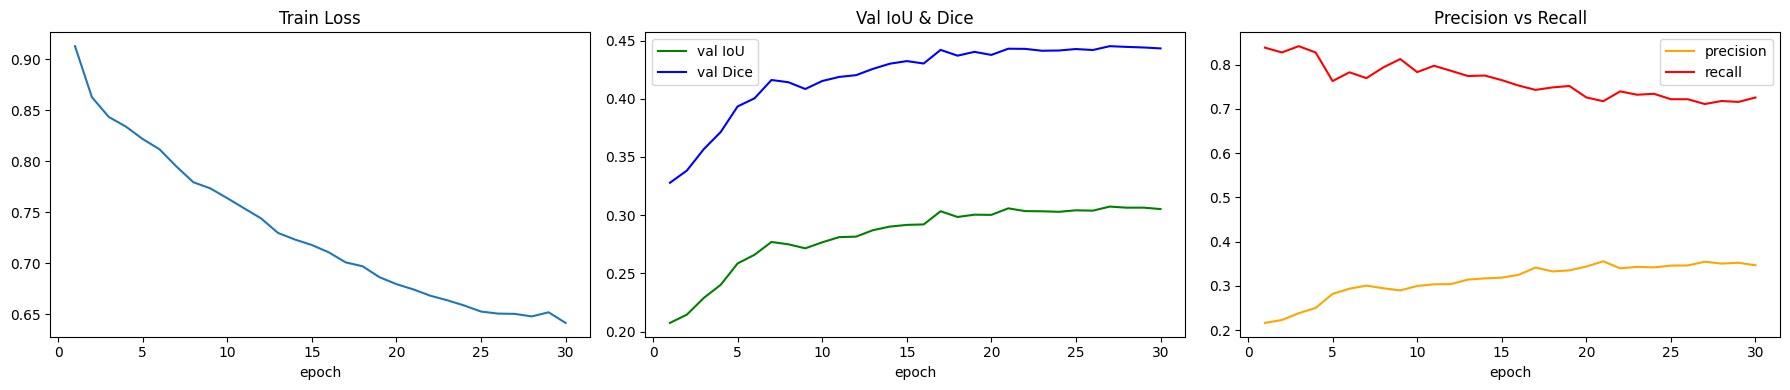

Best epoch: 27 | IoU=0.3074 | Dice=0.4452 | P=0.3547 | R=0.7108


In [21]:
import json
import matplotlib.pyplot as plt
import numpy as np

json.dump(history, open("/kaggle/working/history_finetune.json", "w"))

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
epochs = [h["epoch"] for h in history]
axes[0].plot(epochs, [h["train_loss"]    for h in history], label="train loss")
axes[0].set_title("Train Loss"); axes[0].set_xlabel("epoch")

axes[1].plot(epochs, [h["val_iou"]       for h in history], label="val IoU",   color="green")
axes[1].plot(epochs, [h["val_dice"]      for h in history], label="val Dice",  color="blue")
axes[1].legend(); axes[1].set_title("Val IoU & Dice"); axes[1].set_xlabel("epoch")

axes[2].plot(epochs, [h["val_precision"] for h in history], label="precision", color="orange")
axes[2].plot(epochs, [h["val_recall"]    for h in history], label="recall",    color="red")
axes[2].legend(); axes[2].set_title("Precision vs Recall"); axes[2].set_xlabel("epoch")

plt.tight_layout()
plt.savefig("/kaggle/working/training_curves.png", dpi=90)
plt.show()

best = max(history, key=lambda h: h["val_iou"])
print(f"Best epoch: {best['epoch']} | IoU={best['val_iou']:.4f} | "
      f"Dice={best['val_dice']:.4f} | P={best['val_precision']:.4f} | R={best['val_recall']:.4f}")


## Cell 9 — Inference: Binary PNG + GeoTIFF Masks for Graph Pipeline

In [22]:
import os
import numpy as np
import torch
import rasterio
from rasterio.merge import merge
from rasterio.transform import from_bounds
from torch.cuda.amp import autocast
from PIL import Image
import config

device = torch.device("cuda")

# Load best checkpoint (finetuned preferred, fallback to original)
LOAD_PATHS = [
    "/kaggle/working/terrain_finetuned_best.pth",
    "/kaggle/working/terrain_best_gpu0.pth",
    "/kaggle/working/terrain_best.pth",
]
model.eval()
for lp in LOAD_PATHS:
    if os.path.isfile(lp):
        sd = torch.load(lp, map_location="cpu")
        sd = {k.replace("module.", ""): v for k, v in sd.items()}
        model.load_state_dict(sd, strict=False)
        print(f"[inference] loaded {lp}")
        break

# Anti-flood binarization: per tile, if the predicted road fraction exceeds the
# cap, raise the threshold until the flood is pruned. Fixes LISS-IV predicting
# ~77% road without any retraining. Roads are rarely >50% of a 256x256 tile.
BASE_T   = getattr(config, "INFER_THRESHOLD_START",
              getattr(config, "BEST_THRESHOLD", 0.4))   # 0.4
CAP      = getattr(config, "INFER_MAX_ROAD_FRAC", 0.5)  # 0.5
STEP     = getattr(config, "INFER_THRESHOLD_STEP", 0.05)
MAX_T    = getattr(config, "INFER_THRESHOLD_MAX", 0.9)
ADAPTIVE = getattr(config, "INFER_ADAPTIVE_THRESHOLD", True)

def binarize(prob):
    t = BASE_T
    if not ADAPTIVE:
        return (prob > t).astype(np.uint8) * 255
    while True:
        m = prob > t
        if m.mean() <= CAP or t >= MAX_T:
            return m.astype(np.uint8) * 255
        t = min(MAX_T, t + STEP)

MASK_ROOT = "/kaggle/working/masks"
PROCESSED = os.path.join(config.DATA_DIR, "processed")
os.makedirs(MASK_ROOT, exist_ok=True)

def run_tile(img_path, sensor):
    """Returns (binary_mask uint8 0/255, probability float32 HxW)."""
    from segmentation.dataset import _normalize, _load_norm_stats
    stats = _load_norm_stats()
    with rasterio.open(img_path) as ds:
        arr = ds.read().astype(np.float32)
    img_t = torch.from_numpy(
        _normalize(arr, sensor, stats, config.IN_CHANNELS)
    ).unsqueeze(0).to(device)
    with torch.no_grad(), autocast():
        prob = torch.sigmoid(model(img_t))[0, 0].cpu().numpy()
    binary = binarize(prob)
    return binary, prob

def save_tile_masks(binary, prob, img_path, out_dir, tile_id):
    """Save PNG + georeferenced GeoTIFF for one tile."""
    png_path = os.path.join(out_dir, f"{tile_id}_mask.png")
    Image.fromarray(binary).save(png_path)

    tif_path = os.path.join(out_dir, f"{tile_id}_mask.tif")
    with rasterio.open(img_path) as src:
        profile = src.profile.copy()
    profile.update(count=1, dtype="uint8", compress="lzw", nodata=None)
    with rasterio.open(tif_path, "w", **profile) as dst:
        dst.write(binary[np.newaxis, :, :])
    return tif_path

total = 0
sensor_stats = {}

for sensor in config.TRAIN_SENSORS:
    sensor_dir = os.path.join(PROCESSED, sensor, "image")
    if not os.path.isdir(sensor_dir):
        print(f"  skipping {sensor} - dir not found")
        continue

    out_dir = os.path.join(MASK_ROOT, sensor)
    os.makedirs(out_dir, exist_ok=True)

    fnames   = sorted(os.listdir(sensor_dir))
    tif_paths = []
    road_pcts_before, road_pcts_after = [], []

    for fname in fnames:
        img_path = os.path.join(sensor_dir, fname)
        tile_id  = os.path.splitext(fname)[0]
        try:
            binary, prob = run_tile(img_path, sensor)
            if ADAPTIVE:
                road_pcts_before.append((prob > BASE_T).mean())
                road_pcts_after.append(binary.mean() / 255.0)
            tif_path = save_tile_masks(binary, prob, img_path, out_dir, tile_id)
            tif_paths.append(tif_path)
            total += 1
        except Exception as e:
            print(f"  WARN {fname}: {e}")

    st = {
        "tiles": len(tif_paths),
        "road_pct_mean": float(np.mean(road_pcts_after)) if road_pcts_after else 0.0,
    }
    if ADAPTIVE and road_pcts_before:
        st["road_pct_before"] = float(np.mean(road_pcts_before))
    sensor_stats[sensor] = st

    # Stitch all tiles -> one mosaic GeoTIFF per sensor (input to graph pipeline)
    if tif_paths:
        mosaic_path = os.path.join(MASK_ROOT, f"{sensor}_mosaic.tif")
        datasets = [rasterio.open(p) for p in tif_paths]
        mosaic, transform = merge(datasets)
        for ds in datasets:
            ds.close()
        profile = rasterio.open(tif_paths[0]).profile.copy()
        profile.update(
            height=mosaic.shape[1], width=mosaic.shape[2],
            transform=transform, compress="lzw"
        )
        with rasterio.open(mosaic_path, "w", **profile) as dst:
            dst.write(mosaic)
        if ADAPTIVE:
            print(f"[{sensor}] mosaic -> {mosaic_path}  "
                  f"(road% {st.get('road_pct_before', 0):.3f} -> {st['road_pct_mean']:.3f})")
        else:
            print(f"[{sensor}] mosaic -> {mosaic_path}  "
                  f"(road%={st['road_pct_mean']:.3f})")

print(f"\n=== Inference complete ===")
print(f"Total tiles processed: {total}")
for s, st in sensor_stats.items():
    if ADAPTIVE and "road_pct_before" in st:
        print(f"  {s}: {st['tiles']} tiles | mean road pct: "
              f"{st['road_pct_before']:.3f} -> {st['road_pct_mean']:.3f}")
    else:
        print(f"  {s}: {st['tiles']} tiles | mean road pct: {st['road_pct_mean']:.3f}")
print(f"\nGraph pipeline inputs:")
for sensor in config.TRAIN_SENSORS:
    mp = os.path.join(MASK_ROOT, f"{sensor}_mosaic.tif")
    if os.path.isfile(mp):
        print(f"  {mp}")


## Cell 10 — Sample Visual Overlays (8 Tiles)

/tmp/ipykernel_58/2530634008.py:32: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.no_grad(), torch.cuda.amp.autocast():


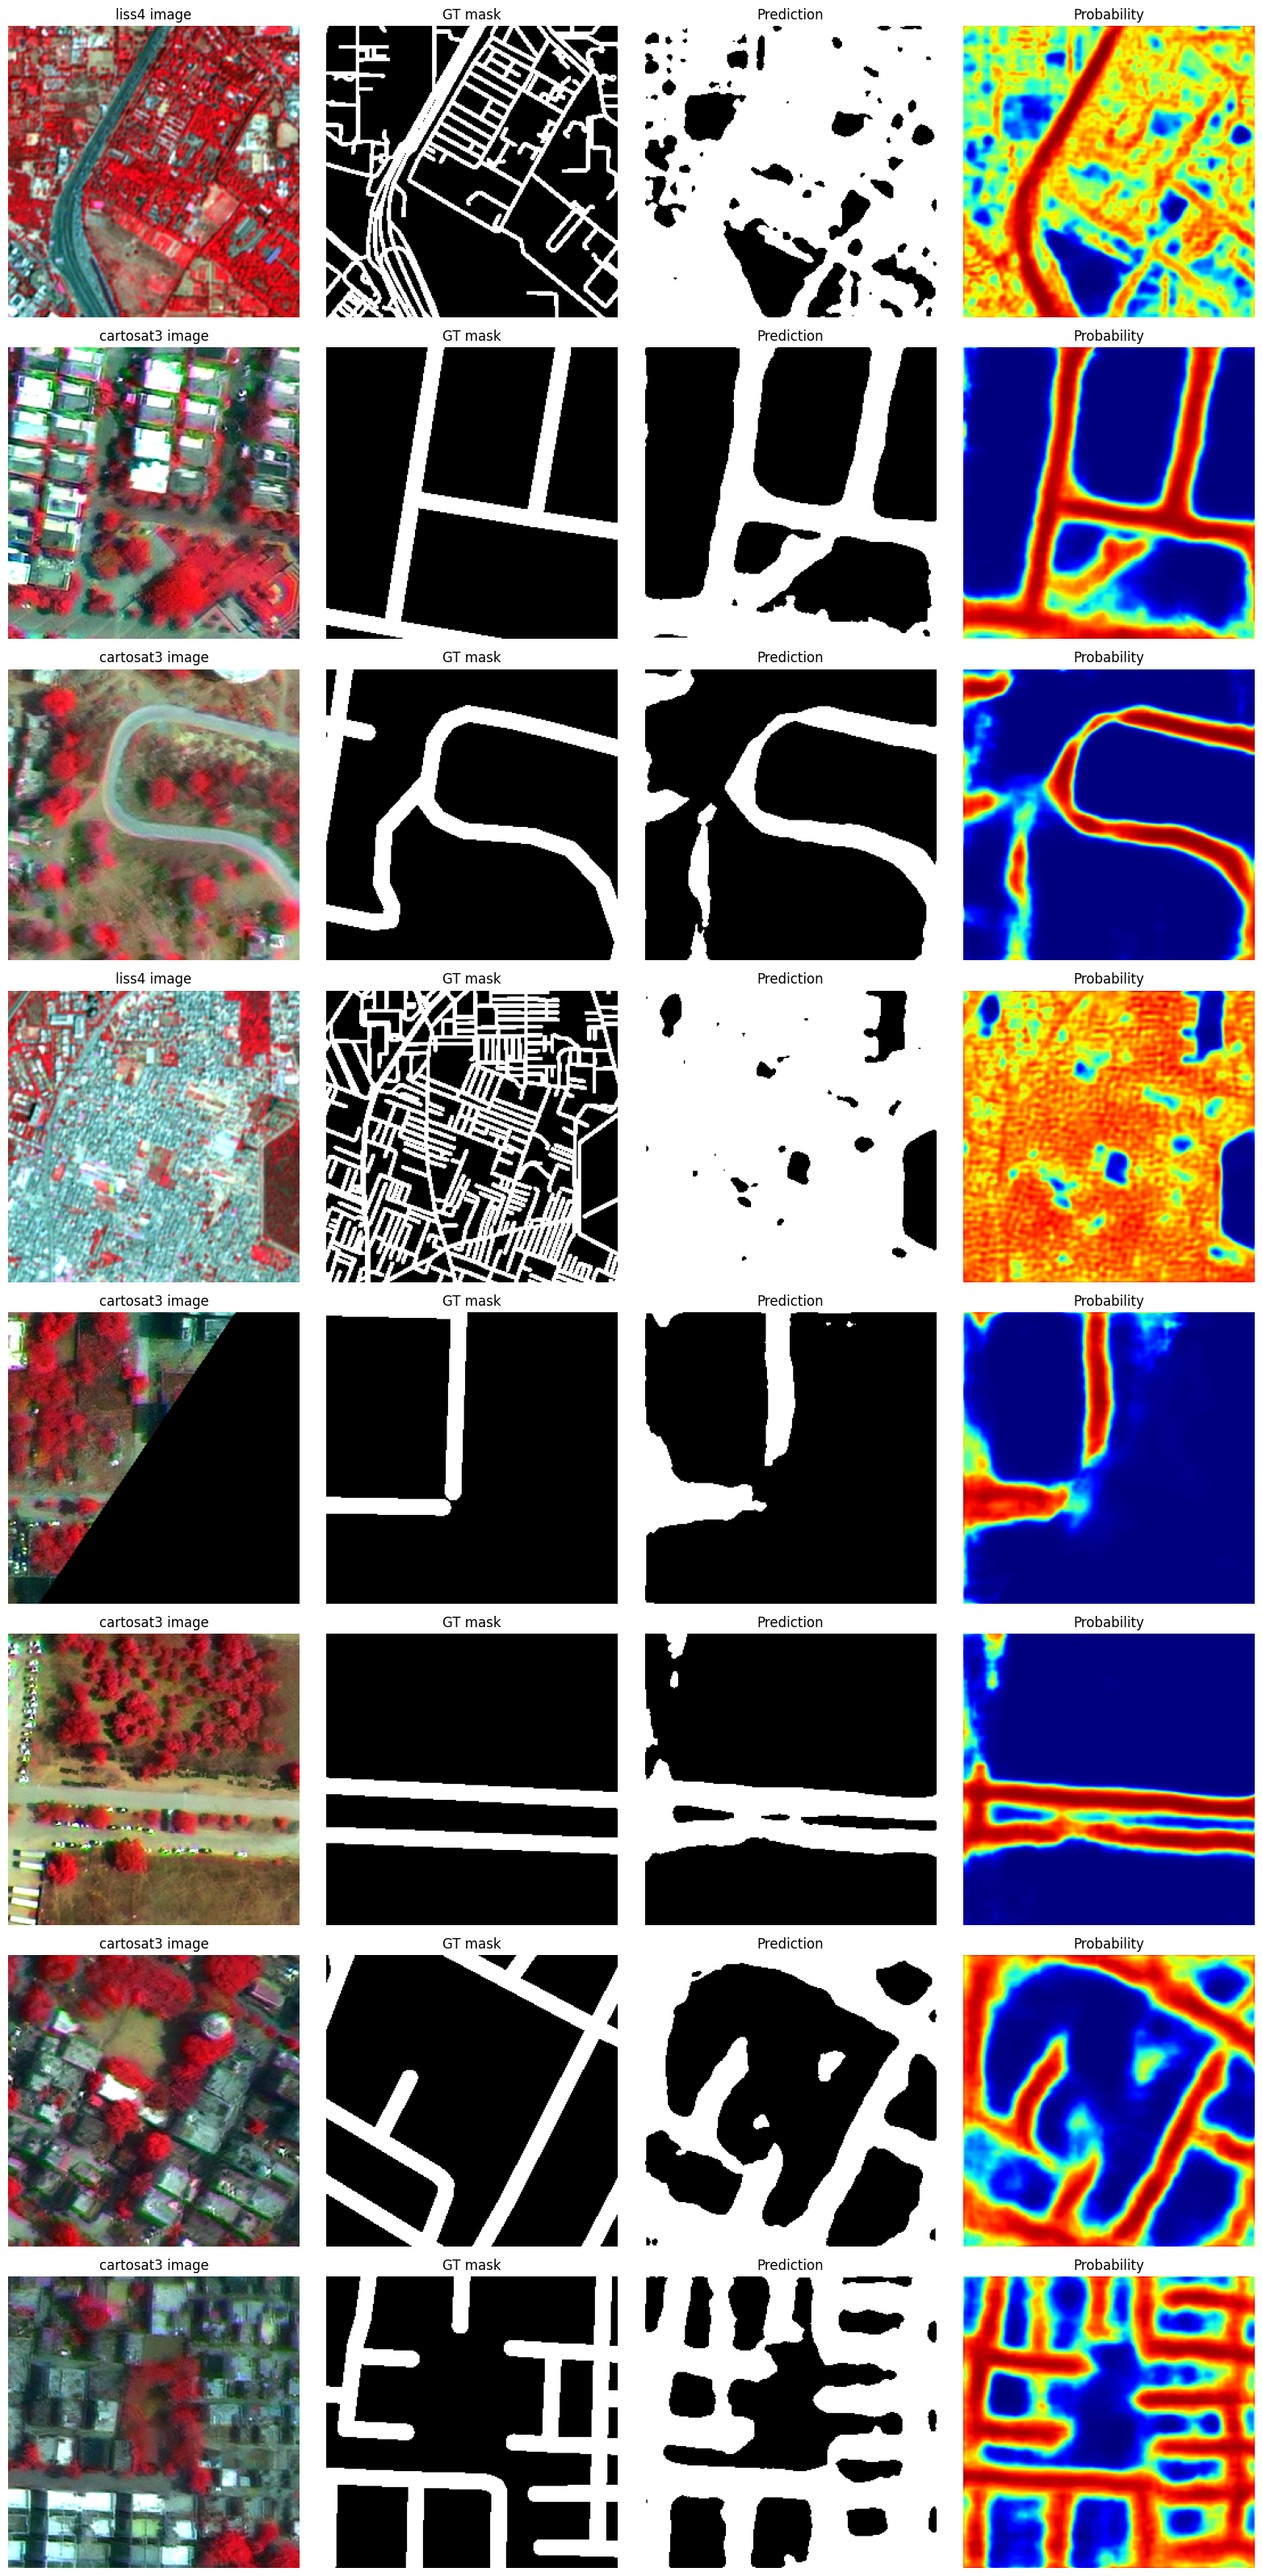

saved /kaggle/working/sample_overlays.png


In [23]:
import random
import matplotlib.pyplot as plt
import numpy as np
import rasterio
import torch
import config
from segmentation.dataset import _normalize, _load_norm_stats

device = torch.device("cuda")
model.eval()
stats = _load_norm_stats()

random.seed(42)
all_items = va.items  # validation tiles
sample    = random.sample(all_items, min(8, len(all_items)))

fig, axes = plt.subplots(len(sample), 4, figsize=(16, 4*len(sample)))
axes = np.atleast_2d(axes)

for r, (sensor, img_path, mask_path) in enumerate(sample):
    with rasterio.open(img_path) as ds:
        arr = ds.read().astype(np.float32)
    img_n = _normalize(arr, sensor, stats, config.IN_CHANNELS)
    rgb   = np.transpose(np.clip(img_n[:3], 0, 1), (1,2,0))

    with rasterio.open(mask_path) as ds:
        gt = ds.read(1).astype(np.float32)
    if gt.max() > 1:
        gt /= 255.0

    img_t = torch.from_numpy(img_n).unsqueeze(0).to(device)
    with torch.no_grad(), torch.cuda.amp.autocast():
        prob = torch.sigmoid(model(img_t))[0,0].cpu().numpy()
    pred = (prob > config.BEST_THRESHOLD).astype(np.float32)

    axes[r,0].imshow(rgb);             axes[r,0].set_title(f"{sensor} image"); axes[r,0].axis("off")
    axes[r,1].imshow(gt,   cmap="gray"); axes[r,1].set_title("GT mask");        axes[r,1].axis("off")
    axes[r,2].imshow(pred, cmap="gray"); axes[r,2].set_title("Prediction");     axes[r,2].axis("off")
    axes[r,3].imshow(prob, cmap="jet", vmin=0, vmax=1)
    axes[r,3].set_title("Probability"); axes[r,3].axis("off")

plt.tight_layout()
plt.savefig("/kaggle/working/sample_overlays.png", dpi=90)
plt.show()
print("saved /kaggle/working/sample_overlays.png")


## Cell 11 — Zip All Artifacts for Download

In [24]:
!zip -q -r /kaggle/working/terrain_outputs.zip \
    /kaggle/working/terrain_finetuned_best.pth \
    /kaggle/working/history_finetune.json \
    /kaggle/working/training_curves.png \
    /kaggle/working/sample_overlays.png \
    /kaggle/working/masks/ \
    -x "*.ipynb_checkpoints*" -x ".*"
!ls -lh /kaggle/working/terrain_outputs.zip
print("DOWNLOAD terrain_outputs.zip from the Output panel.")
print("Mosaic GeoTIFFs for graph pipeline are inside masks/")


-rw-r--r-- 1 root root 190M Aug  6 23:12 /kaggle/working/terrain_outputs.zip
DOWNLOAD terrain_outputs.zip from the Output panel.
Mosaic GeoTIFFs for graph pipeline are inside masks/
